<a href="https://colab.research.google.com/github/IvanZinchenko3214/dap-2024/blob/main/les05/rep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

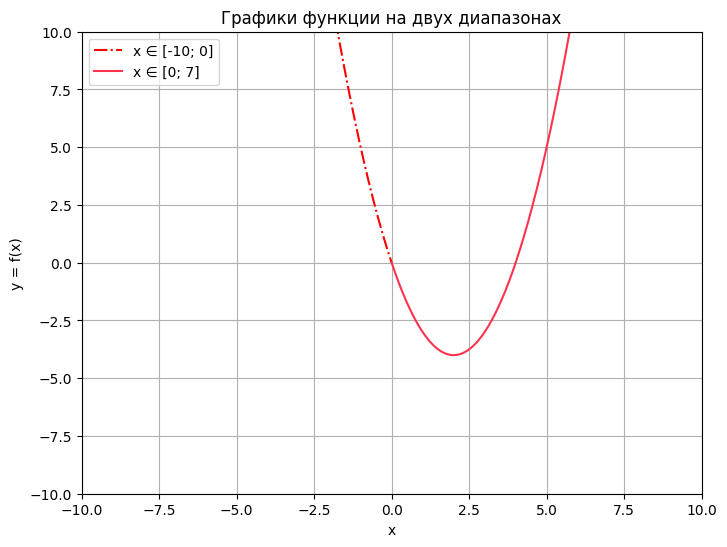

In [2]:
def f(x):
    return x**2 - 4*x

x1 = np.linspace(-10, 0, 200)
x2 = np.linspace(0, 7, 200)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(x1, f(x1), color='red', linestyle='-.', label='x ∈ [-10; 0]')
ax.plot(x2, f(x2), color=(1.0, 0.2, 0.3), linestyle='-', label='x ∈ [0; 7]')

ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_xlabel('x')
ax.set_ylabel('y = f(x)')
ax.set_title('Графики функции на двух диапазонах')
ax.legend()
ax.grid(True)
plt.show()

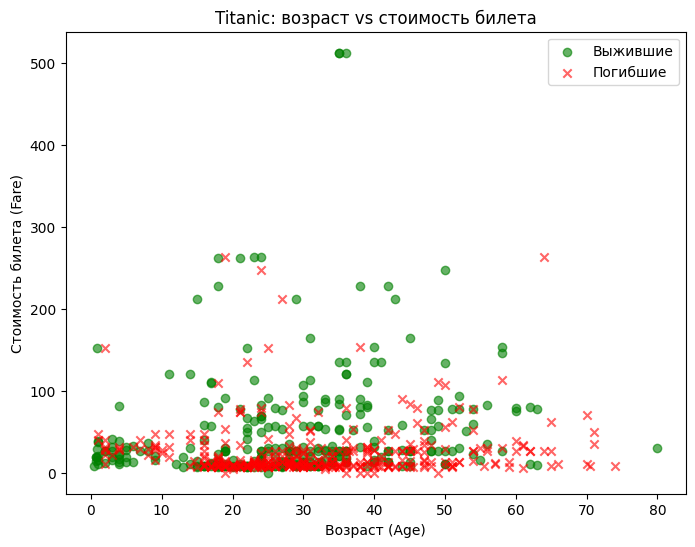

In [5]:
titanic = pd.read_csv('./titanic.csv')

df = titanic.dropna(subset=['Age', 'Fare'])

survived = df[df['Survived'] == 1]
died     = df[df['Survived'] == 0]

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(survived['Age'], survived['Fare'],
           marker='o', color='green', label='Выжившие', alpha=0.6)
ax.scatter(died['Age'], died['Fare'],
           marker='x', color='red', label='Погибшие', alpha=0.6)

ax.set_xlabel('Возраст (Age)')
ax.set_ylabel('Стоимость билета (Fare)')
ax.set_title('Titanic: возраст vs стоимость билета')
ax.legend()
plt.show()

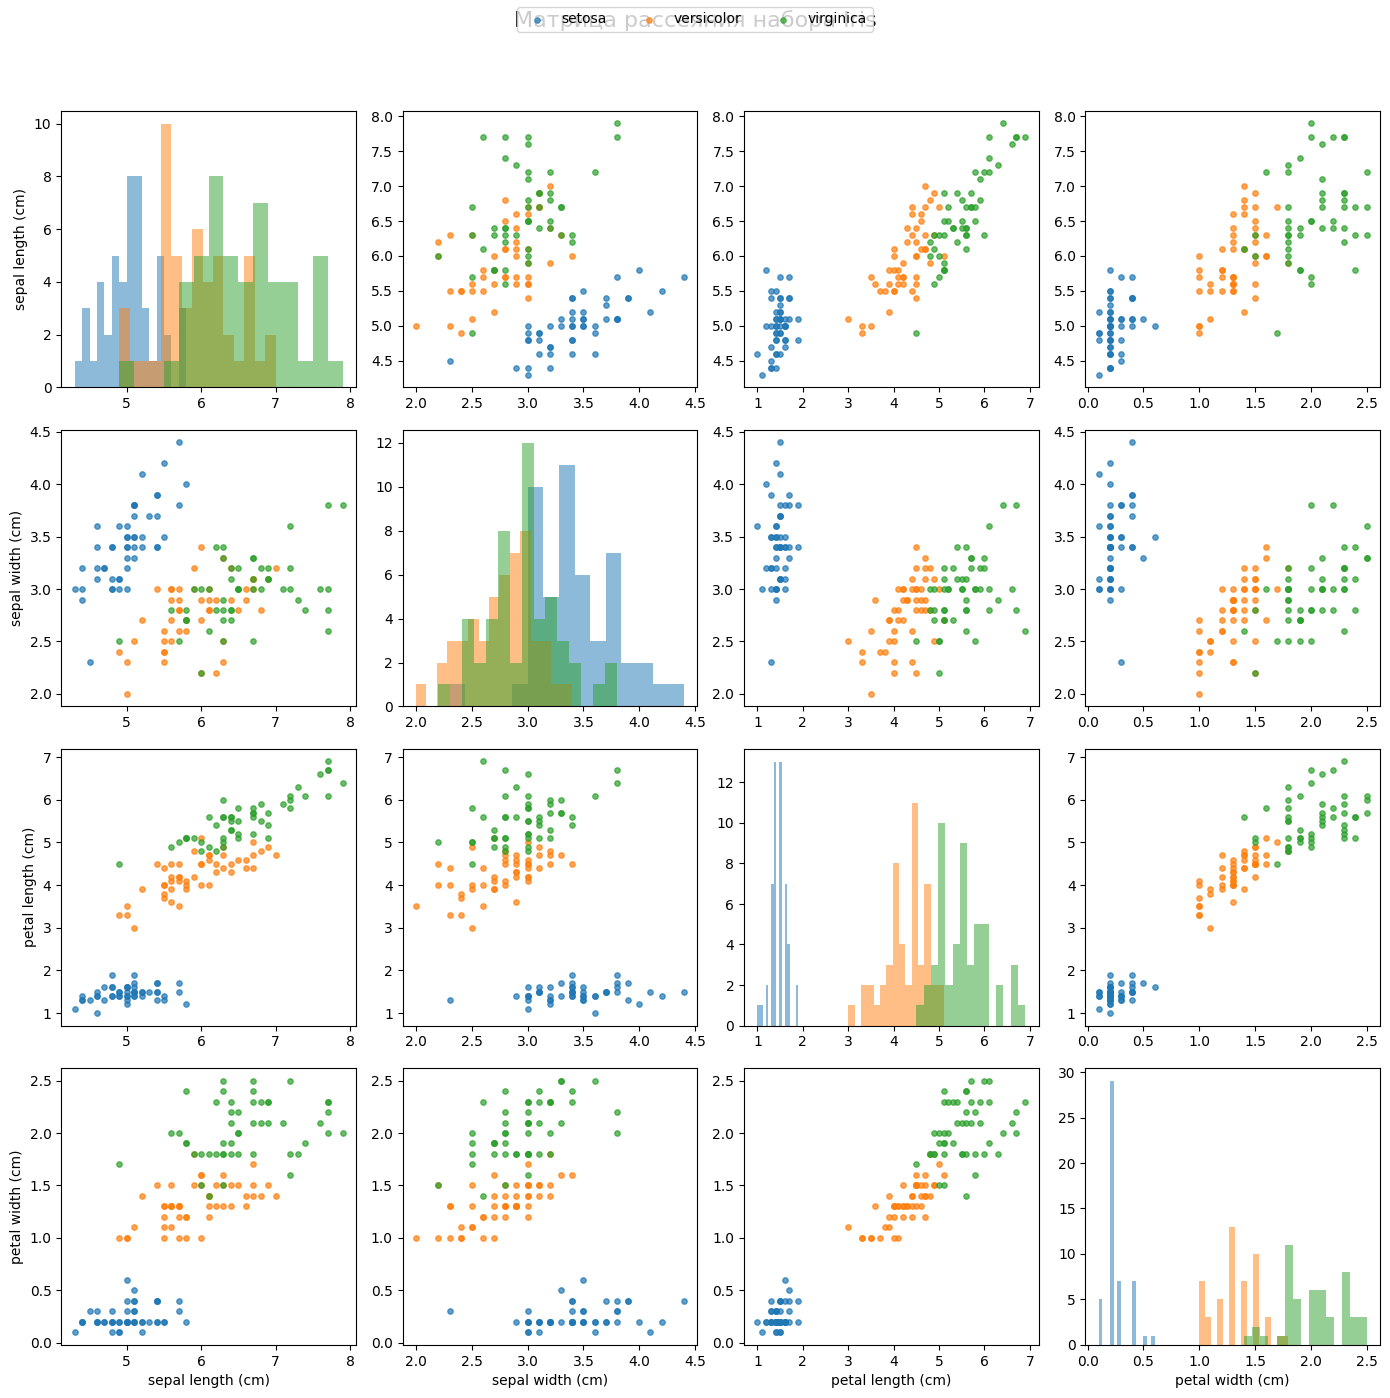

In [6]:
from sklearn.datasets import load_iris
iris = load_iris()

X = iris.data
y = iris.target
feature_names = ['sepal length (cm)', 'sepal width (cm)',
                 'petal length (cm)', 'petal width (cm)']
target_names = iris.target_names
colors = ['tab:blue', 'tab:orange', 'tab:green']

fig, axes = plt.subplots(4, 4, figsize=(14, 14))

for i in range(4):
    for j in range(4):
        ax = axes[i, j]
        if i == j:
            for cls in range(3):
                ax.hist(X[y == cls, i], bins=15, alpha=0.5,
                        color=colors[cls], label=target_names[cls])
        else:
            for cls in range(3):
                ax.scatter(X[y == cls, j], X[y == cls, i],
                           s=15, color=colors[cls], alpha=0.7,
                           label=target_names[cls])
        if i == 3:
            ax.set_xlabel(feature_names[j])
        if j == 0:
            ax.set_ylabel(feature_names[i])

handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3)
fig.suptitle('Матрица рассеяния набора Iris', fontsize=16, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

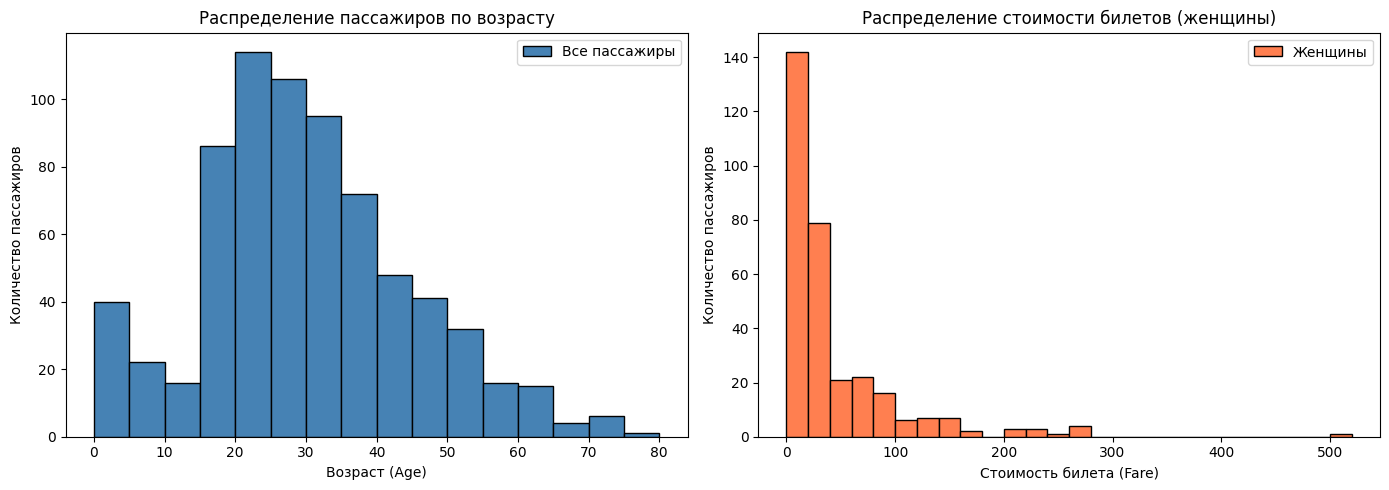

In [8]:
titanic = pd.read_csv('./titanic.csv')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

age = titanic['Age'].dropna()
bins_age = np.arange(0, age.max() + 5, 5)
ax1.hist(age, bins=bins_age, color='steelblue', edgecolor='black')
ax1.set_xlabel('Возраст (Age)')
ax1.set_ylabel('Количество пассажиров')
ax1.set_title('Распределение пассажиров по возрасту')
ax1.legend(['Все пассажиры'])

fare_f = titanic.loc[titanic['Sex'] == 'female', 'Fare'].dropna()

bins_fare = np.arange(0, fare_f.max() + 20, 20)
ax2.hist(fare_f, bins=bins_fare, color='coral', edgecolor='black')
ax2.set_xlabel('Стоимость билета (Fare)')
ax2.set_ylabel('Количество пассажиров')
ax2.set_title('Распределение стоимости билетов (женщины)')
ax2.legend(['Женщины'])

plt.tight_layout()
plt.show()

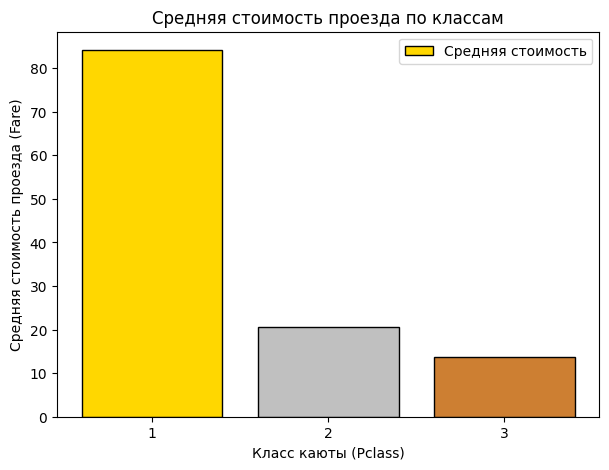

In [9]:
titanic = pd.read_csv('./titanic.csv')

mean_fare = titanic.groupby('Pclass')['Fare'].mean()

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(mean_fare.index.astype(str), mean_fare.values,
       color=['gold', 'silver', '#cd7f32'], edgecolor='black')

ax.set_xlabel('Класс каюты (Pclass)')
ax.set_ylabel('Средняя стоимость проезда (Fare)')
ax.set_title('Средняя стоимость проезда по классам')
ax.legend(['Средняя стоимость'])
plt.show()

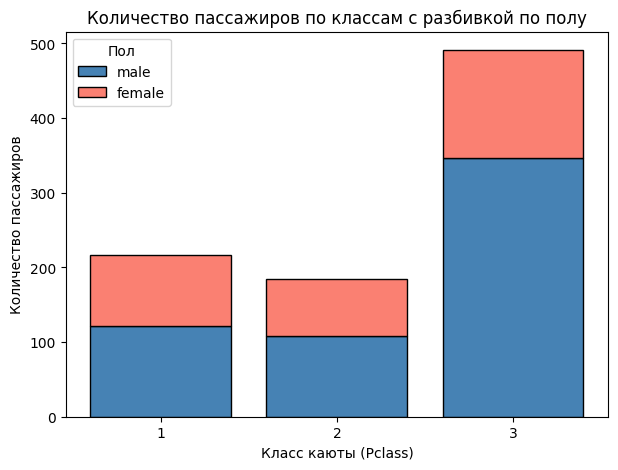

In [10]:
titanic = pd.read_csv('./titanic.csv')

pivot = titanic.groupby(['Pclass', 'Sex']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(7, 5))
bottom = np.zeros(len(pivot))

for sex, color in zip(['male', 'female'], ['steelblue', 'salmon']):
    ax.bar(pivot.index.astype(str), pivot[sex].values,
           bottom=bottom, label=sex, color=color, edgecolor='black')
    bottom += pivot[sex].values

ax.set_xlabel('Класс каюты (Pclass)')
ax.set_ylabel('Количество пассажиров')
ax.set_title('Количество пассажиров по классам с разбивкой по полу')
ax.legend(title='Пол')
plt.show()

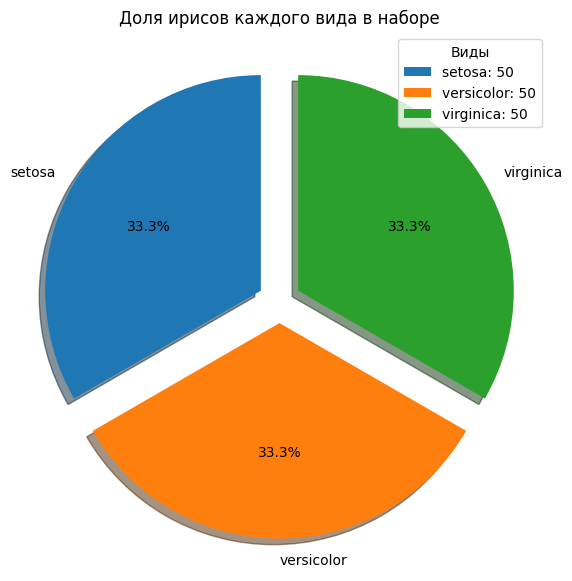

In [11]:
from sklearn.datasets import load_iris
iris = load_iris()

counts = np.bincount(iris.target)
labels = list(iris.target_names)

explode = [0.1 if c == counts.max() else 0 for c in counts]

fig, ax = plt.subplots(figsize=(7, 7))
wedges, texts, autotexts = ax.pie(
    counts, labels=labels, explode=explode, autopct='%1.1f%%',
    startangle=90, shadow=True
)

ax.set_title('Доля ирисов каждого вида в наборе')
ax.legend(wedges, [f'{l}: {c}' for l, c in zip(labels, counts)],
          title='Виды', loc='upper right')
ax.set_xlabel('')
ax.set_ylabel('')
plt.show()

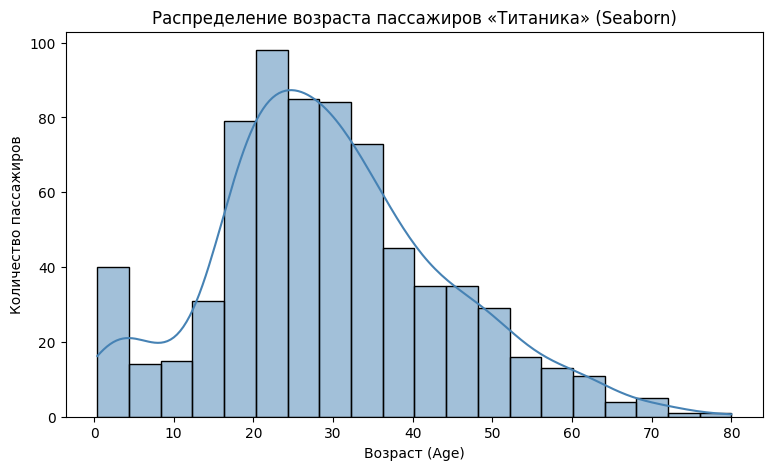

In [12]:
import seaborn as sns

titanic = pd.read_csv('./titanic.csv')

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=titanic, x='Age', bins=20, kde=True,
             color='steelblue', ax=ax)
ax.set_xlabel('Возраст (Age)')
ax.set_ylabel('Количество пассажиров')
ax.set_title('Распределение возраста пассажиров «Титаника» (Seaborn)')
plt.show()